# Practical 5 — K-Means and Hierarchical Clustering on Sales Data

**Subject:** Machine Learning (410242)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Implement **K-Means clustering** and **hierarchical clustering** on the
`sales_data_sample.csv` dataset, and determine the number of clusters using
the **elbow method**.

## 2. Dataset

**Sample Sales Data** — Kaggle:  
<https://www.kaggle.com/datasets/kyanyoga/sample-sales-data>

The dataset contains 2,823 order lines from a scale-model business. Important
columns include:

| Column | Meaning |
|---|---|
| `CUSTOMERNAME` | Customer |
| `ORDERNUMBER` | Order identifier |
| `ORDERDATE` | Order date |
| `QUANTITYORDERED` | Units ordered |
| `PRICEEACH` | Price per unit |
| `SALES` | Line total |
| `PRODUCTLINE`, `COUNTRY`, `DEALSIZE` | Product and geography information |

The CSV is stored as `data/sales_data_sample.csv.gz` and is read with
`latin-1` encoding because some customer names contain non-UTF-8 characters.

## 3. Objectives

- Prepare **RFM** (Recency, Frequency, Monetary) features from raw orders.
- Standardise features before distance-based clustering.
- Use the elbow method and silhouette score to choose $k$.
- Apply K-Means and agglomerative hierarchical clustering.
- Interpret the clusters as customer segments.

## 4. Theory

### 4.1 Unsupervised learning

Clustering is **unsupervised**: there are no labels. The goal is to group
points so that points in the same cluster are similar and points in different
clusters are dissimilar.

### 4.2 K-Means

K-Means partitions $n$ points into $k$ clusters by minimising the
within-cluster sum of squares:

$$J=\sum_{j=1}^{k}\sum_{x_i\in C_j}\|x_i-\mu_j\|^2,$$

where $\mu_j$ is the centroid of cluster $C_j$.

**Lloyd's algorithm:**

1. Choose $k$ initial centroids.
2. Assign each point to the nearest centroid.
3. Recompute each centroid as the mean of its assigned points.
4. Repeat until the assignments stop changing or a maximum number of
   iterations is reached.

K-Means is fast, but it depends on the initial centroids and assumes roughly
spherical clusters. `n_init=20` runs the algorithm 20 times with different
initialisations and keeps the best inertia.

### 4.3 Elbow method

Run K-Means for $k=1,2,\dots,K$ and plot the inertia (WSS). Inertia always
decreases as $k$ increases, but the rate of improvement slows down. The
"elbow" — the point after which adding clusters gives little improvement — is
a candidate for the best $k$. It is a heuristic, not a formal test.

### 4.4 Silhouette score

For a point $i$:

$$a(i)=\text{mean distance to points in its own cluster},$$
$$b(i)=\text{mean distance to points in the nearest other cluster},$$
$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}.$$

The score lies in $[-1,1]$; higher is better. The average silhouette over all
points helps validate the choice of $k$.

### 4.5 Hierarchical clustering

Agglomerative clustering starts with each point as its own cluster and
repeatedly merges the two closest clusters. **Ward's linkage** merges the pair
that increases the within-cluster variance the least. The result is a
**dendrogram**, a tree showing the merge order. Cutting the dendrogram at a
chosen height gives the clusters.

- Time: $O(n^3)$ for the naive algorithm, often $O(n^2\log n)$ with efficient
  priority queues.
- Space: $O(n^2)$ for the distance matrix.

### 4.6 RFM features

Raw order rows are not ideal for customer segmentation because the same
customer appears many times. We aggregate by customer:

- **Recency:** days since the customer's last order (smaller = more recent).
- **Frequency:** number of distinct orders (larger = more loyal).
- **Monetary:** total sales value (larger = more valuable).

These three features are the classic RFM segmentation basis.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("ML/data")

In [2]:
df = pd.read_csv(DATA_DIR / "sales_data_sample.csv.gz", encoding="latin-1")
print("Shape:", df.shape)
print("\nColumns:")
print(df.dtypes.to_string())
df.head()

Shape: (2823, 25)

Columns:
ORDERNUMBER           int64
QUANTITYORDERED       int64
PRICEEACH           float64
ORDERLINENUMBER       int64
SALES               float64
ORDERDATE               str
STATUS                  str
QTR_ID                int64
MONTH_ID              int64
YEAR_ID               int64
PRODUCTLINE             str
MSRP                  int64
PRODUCTCODE             str
CUSTOMERNAME            str
PHONE                   str
ADDRESSLINE1            str
ADDRESSLINE2            str
CITY                    str
STATE                   str
POSTALCODE              str
COUNTRY                 str
TERRITORY               str
CONTACTLASTNAME         str
CONTACTFIRSTNAME        str
DEALSIZE                str


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
print("Missing values (top 10):")
print(df.isna().sum().sort_values(ascending=False).head(10).to_string())
print("\nNumber of customers:", df["CUSTOMERNAME"].nunique())
print("Number of orders   :", df["ORDERNUMBER"].nunique())
print("Date range         :", df["ORDERDATE"].min(), "to", df["ORDERDATE"].max())

Missing values (top 10):
ADDRESSLINE2       2521
STATE              1486
TERRITORY          1074
POSTALCODE           76
SALES                 0
QUANTITYORDERED       0
PRICEEACH             0
ORDERLINENUMBER       0
ORDERNUMBER           0
MONTH_ID              0

Number of customers: 92
Number of orders   : 307
Date range         : 1/10/2003 0:00 to 9/9/2004 0:00


In [4]:
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], errors="coerce")
print("Invalid dates:", df["ORDERDATE"].isna().sum())

Invalid dates: 0


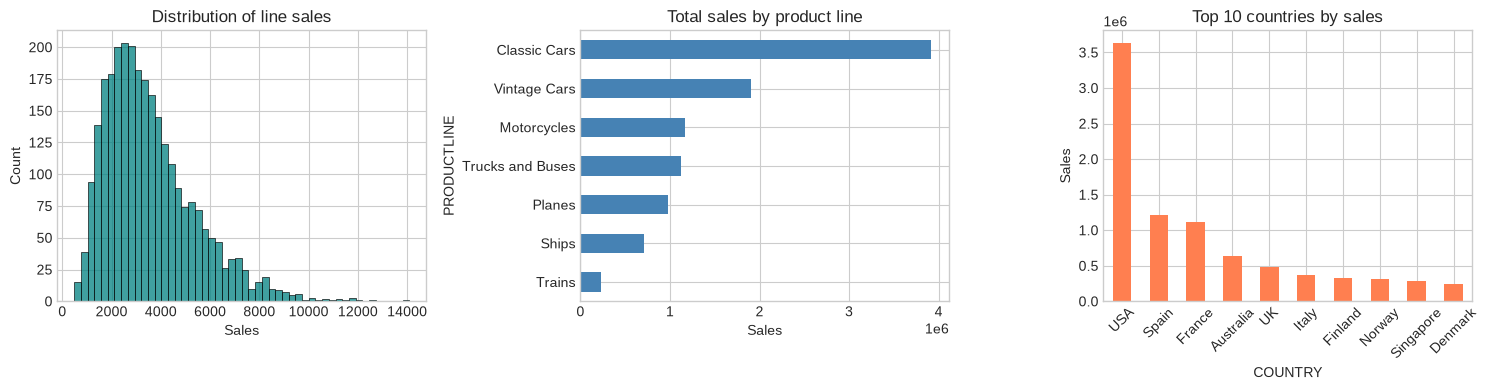

In [5]:
# Sales overview.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["SALES"], bins=50, ax=axes[0], color="teal")
axes[0].set_title("Distribution of line sales")
axes[0].set_xlabel("Sales")

df.groupby("PRODUCTLINE")["SALES"].sum().sort_values().plot(
    kind="barh", ax=axes[1], color="steelblue"
)
axes[1].set_title("Total sales by product line")
axes[1].set_xlabel("Sales")

df.groupby("COUNTRY")["SALES"].sum().sort_values(ascending=False).head(10).plot(
    kind="bar", ax=axes[2], color="coral"
)
axes[2].set_title("Top 10 countries by sales")
axes[2].set_ylabel("Sales")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 4.1 Building the RFM table

The snapshot date is one day after the last order in the dataset. Recency is
measured relative to this date.

In [6]:
snapshot_date = df["ORDERDATE"].max() + pd.Timedelta(days=1)

rfm = (
    df.groupby("CUSTOMERNAME")
    .agg(
        recency=("ORDERDATE", lambda dates: (snapshot_date - dates.max()).days),
        frequency=("ORDERNUMBER", "nunique"),
        monetary=("SALES", "sum"),
    )
    .reset_index()
)

print("Snapshot date:", snapshot_date.date())
print("RFM shape    :", rfm.shape)
rfm.head()

Snapshot date: 2005-06-01
RFM shape    : (92, 4)


,CUSTOMERNAME,recency,frequency,monetary
0,"AV Stores, Co.",196,3,157807.81
1,Alpha Cognac,65,3,70488.44
2,Amica Models & Co.,265,2,94117.26
3,"Anna's Decorations, Ltd",84,4,153996.13
4,Atelier graphique,188,3,24179.96


In [7]:
rfm[["recency", "frequency", "monetary"]].describe().T

,count,mean,std,min,25%,50%,75%,max
recency,92.0,182.826087,131.420524,1.00,81.2500,186.00,230.250,509.00
frequency,92.0,3.336957,2.924986,1.00,2.0000,3.00,3.000,26.00
monetary,92.0,109050.313587,110308.612808,9129.35,70129.4325,86522.61,120575.875,912294.11


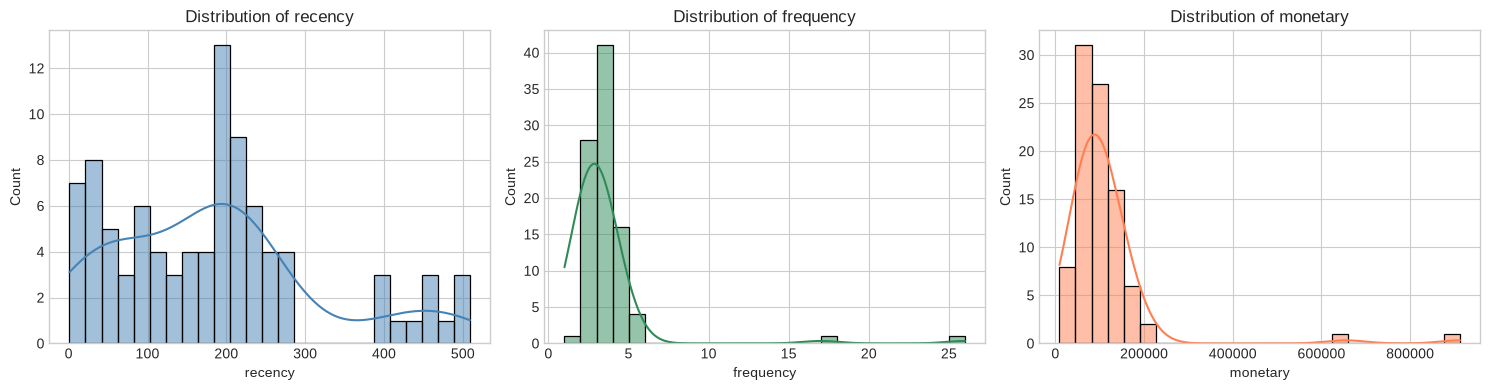

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, column, colour in zip(
    axes,
    ["recency", "frequency", "monetary"],
    ["steelblue", "seagreen", "coral"],
):
    sns.histplot(rfm[column], bins=25, ax=axis, color=colour, kde=True)
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(column)
plt.tight_layout()
plt.show()

In [9]:
# Standardise the RFM features. K-Means uses Euclidean distance, so features
# with larger numeric ranges (monetary) would otherwise dominate.
rfm_features = ["recency", "frequency", "monetary"]
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[rfm_features])

print("Scaled feature means:", np.round(rfm_scaled.mean(axis=0), 6))
print("Scaled feature stds :", np.round(rfm_scaled.std(axis=0), 6))

Scaled feature means: [-0.  0. -0.]
Scaled feature stds : [1. 1. 1.]


### 4.2 Elbow method

We fit K-Means for $k=1,\dots,10$ and record the inertia. The percentage drop
from one $k$ to the next makes the elbow easier to see.

In [10]:
k_values = list(range(1, 11))
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(rfm_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(
        silhouette_score(rfm_scaled, labels) if k > 1 else np.nan
    )

elbow_table = pd.DataFrame(
    {
        "k": k_values,
        "inertia (WSS)": inertias,
        "inertia drop %": [np.nan]
        + [
            100 * (inertias[index - 1] - inertias[index]) / inertias[index - 1]
            for index in range(1, len(inertias))
        ],
        "silhouette": silhouettes,
    }
)
elbow_table

,k,inertia (WSS),inertia drop %,silhouette
0,1,276.000000,NaN,NaN
1,2,115.102340,58.296254,0.849239
2,3,56.807384,50.646195,0.491625
3,4,30.938751,45.537448,0.494494
4,5,23.399650,24.367826,0.482954
5,6,17.727282,24.241252,0.402983
6,7,14.185020,19.981979,0.385626
7,8,11.127214,21.556590,0.410342
8,9,9.802322,11.906773,0.415943
9,10,8.572801,12.543154,0.412636


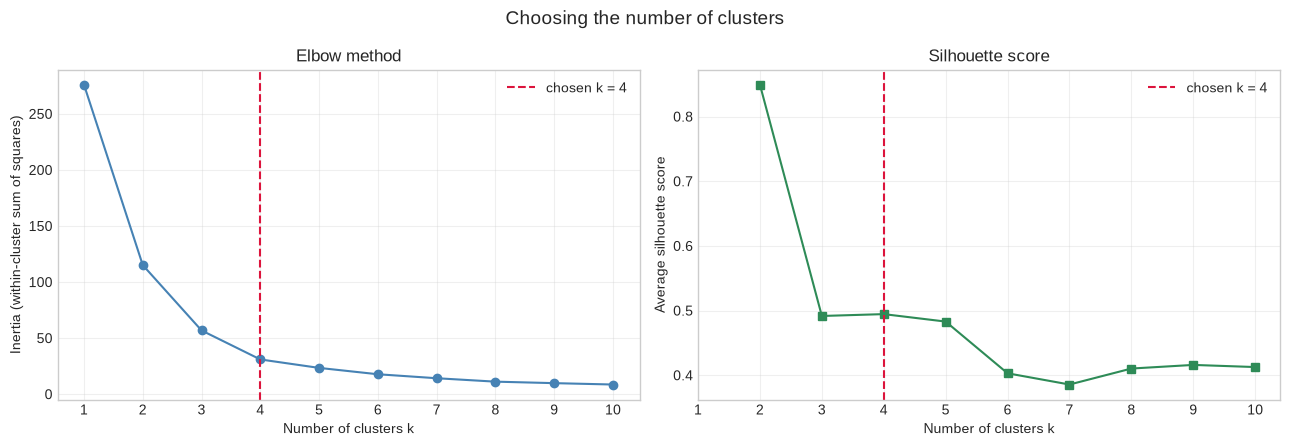

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(elbow_table["k"], elbow_table["inertia (WSS)"], "o-", color="steelblue")
axes[0].axvline(4, color="crimson", linestyle="--", label="chosen k = 4")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_title("Elbow method")
axes[0].set_xticks(k_values)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(elbow_table["k"], elbow_table["silhouette"], "s-", color="seagreen")
axes[1].axvline(4, color="crimson", linestyle="--", label="chosen k = 4")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Average silhouette score")
axes[1].set_title("Silhouette score")
axes[1].set_xticks(k_values)
axes[1].legend()
axes[1].grid(alpha=0.3)

figure.suptitle("Choosing the number of clusters", fontsize=14)
plt.tight_layout()
plt.show()

**Choosing $k$:** the inertia curve flattens after $k=4$, and the silhouette
has a local peak at $k=4$. Although $k=2$ gives a higher silhouette (it simply
separates the very large customers), four clusters give a more useful
business segmentation: VIP, recent mid-value, dormant mid-value and
at-risk/lost customers. We therefore use $k=4$.

In [12]:
k = 4
kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
rfm["cluster"] = kmeans.fit_predict(rfm_scaled)

print("K-Means inertia:", round(kmeans.inertia_, 2))
print("Cluster counts:")
print(rfm["cluster"].value_counts().sort_index())

K-Means inertia: 30.94
Cluster counts:
cluster
0    29
1     2
2    12
3    49
Name: count, dtype: int64


In [13]:
# Convert the centroids back to the original RFM scale.
centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=rfm_features,
)

profile = rfm.groupby("cluster").agg(
    customers=("CUSTOMERNAME", "size"),
    recency_mean=("recency", "mean"),
    frequency_mean=("frequency", "mean"),
    monetary_mean=("monetary", "mean"),
    monetary_total=("monetary", "sum"),
)
profile = profile.join(centers, rsuffix="_center")
profile.round(2).sort_values("monetary_mean", ascending=False)

,customers,recency_mean,frequency_mean,monetary_mean,monetary_total,recency,frequency,monetary
cluster,,,,,,,,
1,2,2.00,21.50,783576.08,1567152.17,2.00,21.50,783576.09
0,29,51.97,3.52,114589.80,3323104.11,51.97,3.52,114589.80
3,49,202.43,2.80,88955.99,4358843.44,202.43,2.80,88955.99
2,12,449.17,2.08,65294.09,783529.13,449.17,2.08,65294.09


In [14]:
# Give each cluster a readable segment name based on its profile.
profile_sorted = profile.sort_values("monetary_mean", ascending=False)
segment_names = {}

# The highest-monetary cluster is the VIP segment. Of the remaining clusters,
# recent ones are labelled "Recent / mid-value" and older ones "Dormant /
# at-risk". The lowest-monetary of the dormant groups becomes "Low-value / lost".
segment_names = {
    cluster_id: (
        "VIP / high-value"
        if cluster_id == profile_sorted.index[0]
        else (
            "Recent / mid-value"
            if profile.loc[cluster_id, "recency_mean"]
            <= profile["recency_mean"].median()
            else "Dormant / at-risk"
        )
    )
    for cluster_id in profile.index
}

remaining = [
    cluster_id
    for cluster_id in profile.index
    if segment_names[cluster_id] == "Dormant / at-risk"
]
remaining.sort(key=lambda cluster_id: profile.loc[cluster_id, "monetary_mean"])
if len(remaining) >= 2:
    segment_names[remaining[0]] = "Low-value / lost"

rfm["segment"] = rfm["cluster"].map(segment_names)
rfm[["CUSTOMERNAME", "recency", "frequency", "monetary", "cluster", "segment"]].head()

,CUSTOMERNAME,recency,frequency,monetary,cluster,segment
0,"AV Stores, Co.",196,3,157807.81,3,Dormant / at-risk
1,Alpha Cognac,65,3,70488.44,0,Recent / mid-value
2,Amica Models & Co.,265,2,94117.26,3,Dormant / at-risk
3,"Anna's Decorations, Ltd",84,4,153996.13,0,Recent / mid-value
4,Atelier graphique,188,3,24179.96,3,Dormant / at-risk


In [15]:
segment_summary = (
    rfm.groupby(["cluster", "segment"])
    .agg(
        customers=("CUSTOMERNAME", "size"),
        recency_mean=("recency", "mean"),
        frequency_mean=("frequency", "mean"),
        monetary_mean=("monetary", "mean"),
        monetary_total=("monetary", "sum"),
    )
    .round(2)
    .sort_values("monetary_mean", ascending=False)
)
segment_summary

,,customers,recency_mean,frequency_mean,monetary_mean,monetary_total
cluster,segment,,,,,
1,VIP / high-value,2,2.00,21.50,783576.08,1567152.17
0,Recent / mid-value,29,51.97,3.52,114589.80,3323104.11
3,Dormant / at-risk,49,202.43,2.80,88955.99,4358843.44
2,Low-value / lost,12,449.17,2.08,65294.09,783529.13


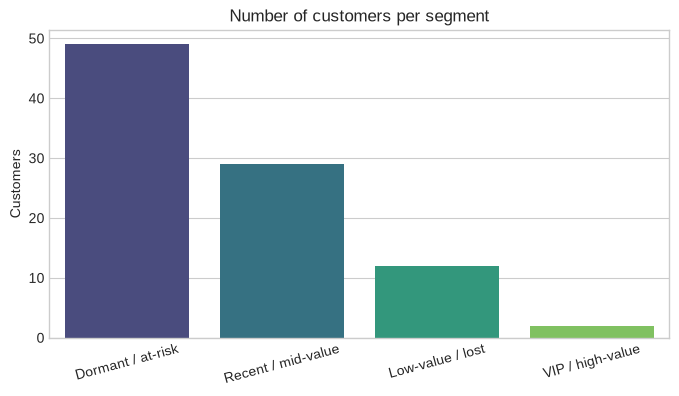

In [16]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=rfm,
    x="segment",
    order=rfm["segment"].value_counts().index,
    palette="viridis",
)
plt.title("Number of customers per segment")
plt.xlabel("")
plt.ylabel("Customers")
plt.xticks(rotation=15)
plt.show()

### 4.3 Visualising the K-Means clusters

Recency is plotted on the x-axis and monetary value on a logarithmic y-axis.
The centroids are marked with black crosses. A good segmentation separates
recent high-value customers from old low-value customers.

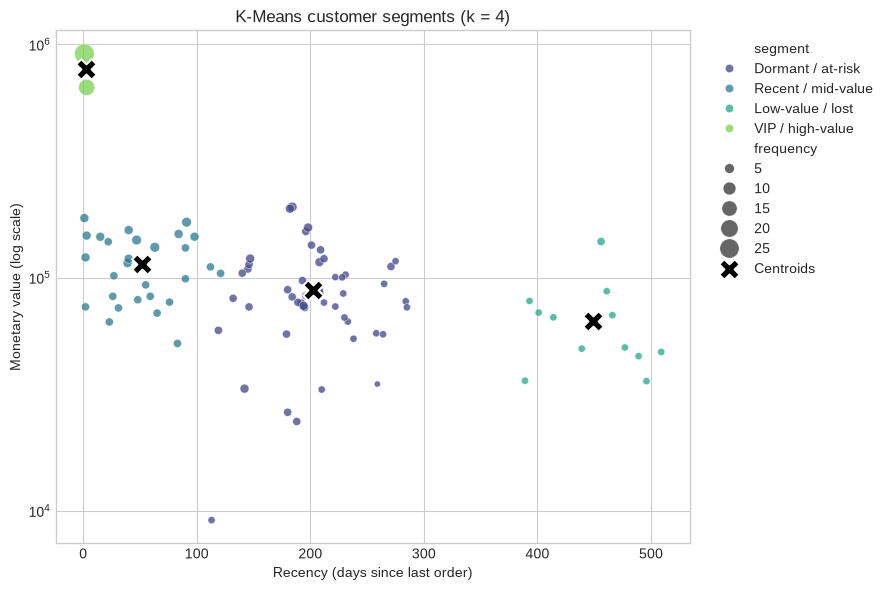

In [17]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="recency",
    y="monetary",
    hue="segment",
    size="frequency",
    sizes=(20, 200),
    alpha=0.75,
    palette="viridis",
)
plt.scatter(
    centers["recency"],
    centers["monetary"],
    marker="X",
    s=220,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids",
    zorder=5,
)
plt.yscale("log")
plt.xlabel("Recency (days since last order)")
plt.ylabel("Monetary value (log scale)")
plt.title("K-Means customer segments (k = 4)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

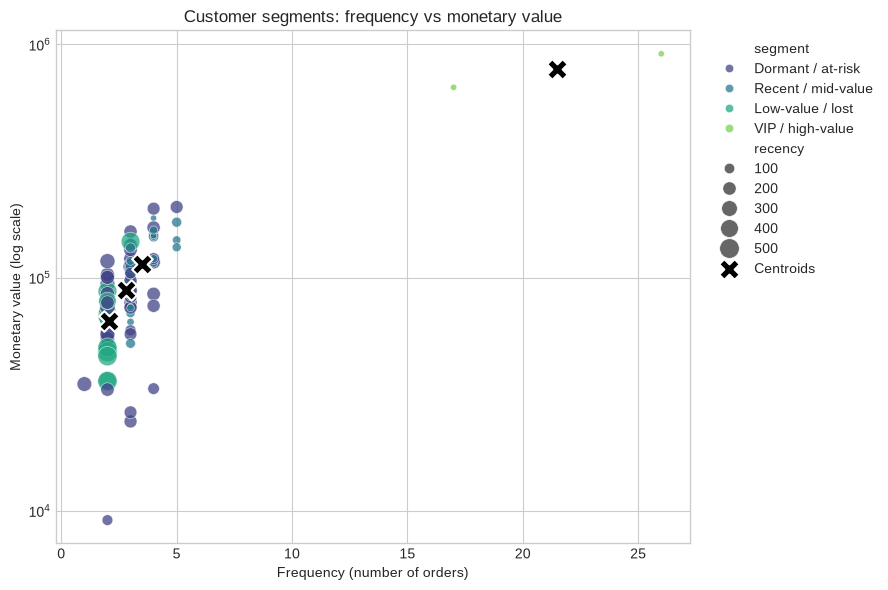

In [18]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="frequency",
    y="monetary",
    hue="segment",
    size="recency",
    sizes=(20, 200),
    alpha=0.75,
    palette="viridis",
)
plt.scatter(
    centers["frequency"],
    centers["monetary"],
    marker="X",
    s=220,
    color="black",
    edgecolor="white",
    linewidth=1.5,
    label="Centroids",
    zorder=5,
)
plt.yscale("log")
plt.xlabel("Frequency (number of orders)")
plt.ylabel("Monetary value (log scale)")
plt.title("Customer segments: frequency vs monetary value")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.4 Hierarchical clustering

The dendrogram shows the merge order. Cutting it at four clusters gives the
agglomerative solution. We then compare the K-Means and hierarchical labels
using the **Adjusted Rand Index (ARI)**:

$$\text{ARI}=1 \Rightarrow \text{identical partitions},\qquad
\text{ARI}\approx 0 \Rightarrow \text{random labelling}.$$

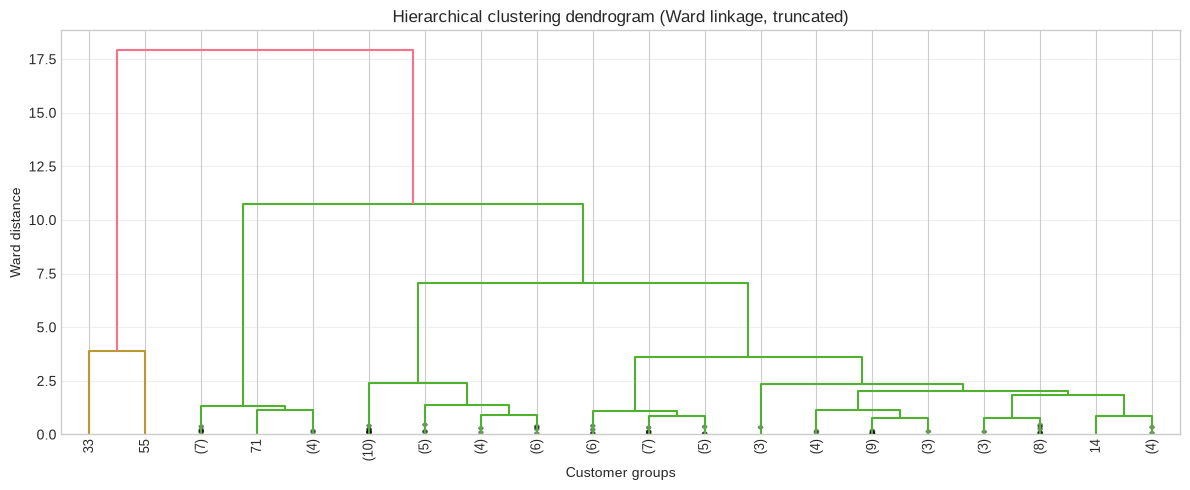

In [19]:
linkage_matrix = linkage(rfm_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=20,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True,
)
plt.title("Hierarchical clustering dendrogram (Ward linkage, truncated)")
plt.xlabel("Customer groups")
plt.ylabel("Ward distance")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
hierarchical = AgglomerativeClustering(n_clusters=k, linkage="ward")
rfm["hierarchical_cluster"] = hierarchical.fit_predict(rfm_scaled)

ari = adjusted_rand_score(rfm["cluster"], rfm["hierarchical_cluster"])
print("Adjusted Rand Index (K-Means vs hierarchical):", round(ari, 4))
print("\nCluster counts (hierarchical):")
print(rfm["hierarchical_cluster"].value_counts().sort_index())

Adjusted Rand Index (K-Means vs hierarchical): 0.8534

Cluster counts (hierarchical):
hierarchical_cluster
0     2
1    53
2    12
3    25
Name: count, dtype: int64


In [21]:
crosstab = pd.crosstab(
    rfm["cluster"], rfm["hierarchical_cluster"], rownames=["K-Means"], colnames=["Hierarchical"]
)
crosstab

Hierarchical,0,1,2,3
K-Means,,,,
0,0,4,0,25
1,2,0,0,0
2,0,0,12,0
3,0,49,0,0


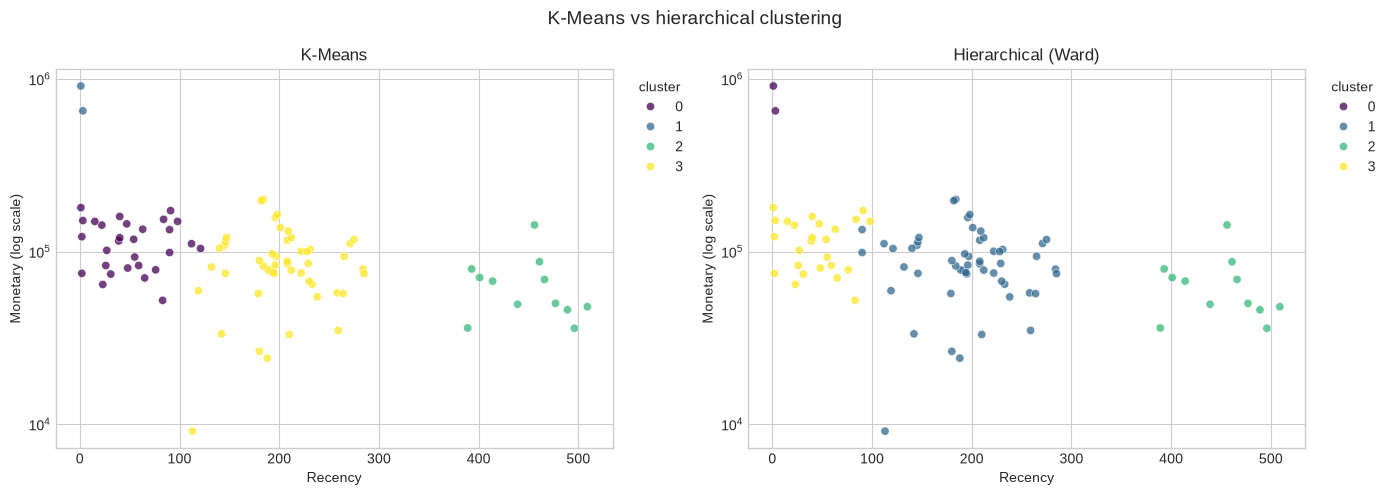

In [22]:
# Compare the two clusterings visually.
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, column, title in [
    (axes[0], "cluster", "K-Means"),
    (axes[1], "hierarchical_cluster", "Hierarchical (Ward)"),
]:
    sns.scatterplot(
        data=rfm,
        x="recency",
        y="monetary",
        hue=column,
        palette="viridis",
        alpha=0.75,
        ax=axis,
    )
    axis.set_yscale("log")
    axis.set_xlabel("Recency")
    axis.set_ylabel("Monetary (log scale)")
    axis.set_title(title)
    axis.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.suptitle("K-Means vs hierarchical clustering", fontsize=14)
plt.tight_layout()
plt.show()

### 4.5 Predicting the segment of a new customer

A fitted K-Means model can assign a segment to a new customer by scaling the
new RFM vector with the **same** scaler and finding the nearest centroid.

In [23]:
new_customers = pd.DataFrame(
    {
        "recency": [10, 60, 400],
        "frequency": [20, 3, 1],
        "monetary": [500_000, 100_000, 20_000],
    }
)

new_scaled = scaler.transform(new_customers[rfm_features])
new_customers["cluster"] = kmeans.predict(new_scaled)
new_customers["segment"] = new_customers["cluster"].map(segment_names)
new_customers

,recency,frequency,monetary,cluster,segment
0,10,20,500000,1,VIP / high-value
1,60,3,100000,0,Recent / mid-value
2,400,1,20000,2,Low-value / lost


In [24]:
# Test cases and sanity checks.
assert rfm["cluster"].nunique() == k
assert rfm["hierarchical_cluster"].nunique() == k
assert rfm["cluster"].value_counts().sum() == len(rfm)
assert -1 <= ari <= 1
print("All clustering checks passed ✓")
print("Customers:", len(rfm), "| Segments:", k)

All clustering checks passed ✓
Customers: 92 | Segments: 4


In [25]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - ML Practical 5 (Customer clustering)")
print("=" * 78)
print(
    "Clustering is unsupervised: there are no correct labels to compare with.\n"
    "The output is judged by whether the clusters are stable, interpretable and\n"
    "useful for a business decision. RFM means Recency, Frequency and Monetary\n"
    "value; each row below is a customer, not an individual order."
)

print("\n1. DATA AND RFM AGGREGATION")
print("-" * 78)
print(f"Raw order rows       : {len(df):,}")
print(f"Columns              : {df.shape[1]}")
print(f"Customers in RFM     : {len(rfm):,}")
print(f"Distinct orders      : {df['ORDERNUMBER'].nunique():,}")
print(f"Date range           : {df['ORDERDATE'].min().date()} to {df['ORDERDATE'].max().date()}")
print("RFM statistics:")
rfm_stats = rfm[["recency", "frequency", "monetary"]].describe().T
for feature, row in rfm_stats.iterrows():
    print(
        f"  {feature:10s}: mean={row['mean']:.2f}, std={row['std']:.2f}, "
        f"min={row['min']:.2f}, max={row['max']:.2f}"
    )
print("Recency is days since the last order (smaller is better). Frequency is")
print("the number of distinct orders. Monetary is total sales value. Aggregating")
print("orders into customer-level RFM prevents one frequent buyer from being")
print("treated as many independent data points.")

print("\n2. CHOOSING k WITH THE ELBOW AND SILHOUETTE")
print("-" * 78)
for _, row in elbow_table.iterrows():
    inertia_drop = row["inertia drop %"]
    drop_text = "n/a" if pd.isna(inertia_drop) else f"{inertia_drop:.2f}%"
    silhouette_text = "n/a" if pd.isna(row["silhouette"]) else f"{row['silhouette']:.4f}"
    print(
        f"  k={int(row['k']):2d}: inertia={row['inertia (WSS)']:.2f}, "
        f"drop={drop_text}, silhouette={silhouette_text}"
    )
selected_elbow = elbow_table.loc[elbow_table["k"] == k].iloc[0]
best_silhouette = elbow_table.dropna(subset=["silhouette"]).sort_values(
    "silhouette", ascending=False
).iloc[0]
print(f"Chosen k: {k}")
print(
    f"Selected-k inertia drop: {selected_elbow['inertia drop %']:.2f}%, "
    f"silhouette={selected_elbow['silhouette']:.4f}"
)
print(
    f"Highest silhouette occurs at k={int(best_silhouette['k'])} "
    f"({best_silhouette['silhouette']:.4f}), but the elbow and business"
)
print("interpretability favour k=4. The k=2 solution is mostly a split between")
print("a few enormous customers and everyone else, which is less actionable.")
print("The elbow method is a heuristic, not a formal statistical test.")

print("\n3. K-MEANS SEGMENTS")
print("-" * 78)
print(f"K-Means inertia at k={k}: {kmeans.inertia_:.2f}")
for _, row in profile.sort_values("monetary_mean", ascending=False).iterrows():
    cluster_id = int(row.name)
    segment_name = segment_names.get(cluster_id, "unlabelled")
    print(
        f"  cluster {cluster_id} ({segment_name}): "
        f"customers={int(row['customers'])}, "
        f"recency={row['recency_mean']:.1f} days, "
        f"frequency={row['frequency_mean']:.1f} orders, "
        f"monetary mean=${row['monetary_mean']:,.0f}, "
        f"total=${row['monetary_total']:,.0f}"
    )
print("Interpretation of the labels:")
print("  VIP / high-value      : recent, frequent, highest spending.")
print("  Recent / mid-value    : recently active with moderate spending.")
print("  Dormant / at-risk     : last order long ago; win-back candidate.")
print("  Low-value / lost      : oldest and smallest spenders.")
print("The labels are assigned from the data, not from pre-existing ground truth.")

print("\n4. HIERARCHICAL CLUSTERING AND AGREEMENT")
print("-" * 78)
print(f"Ward linkage matrix shape: {linkage_matrix.shape}")
print(f"Adjusted Rand Index (K-Means vs Ward): {ari:.4f}")
print("ARI=1 means identical partitions; ARI near 0 means agreement no better")
print("than chance. A high value here means two very different algorithms found")
print("a similar customer structure, which increases confidence in the segments.")
print("Crosstab of cluster assignments (K-Means rows, hierarchical columns):")
print(crosstab.to_string())

print("\n5. NEW CUSTOMER ASSIGNMENTS")
print("-" * 78)
for _, row in new_customers.iterrows():
    print(
        f"  recency={int(row['recency']):3d} days, "
        f"frequency={int(row['frequency']):2d}, "
        f"monetary=${int(row['monetary']):,} -> "
        f"cluster {int(row['cluster'])}, segment={row['segment']}"
    )
print("The new RFM vector is scaled with the same scaler and assigned to the")
print("nearest centroid. This is how the fitted model can score a customer who")
print("was not present when the clusters were learned.")

print("\n6. TAKEAWAY")
print("-" * 78)
print("Standardise features before K-Means or Ward clustering; otherwise")
print("monetary value (tens of thousands) would dominate frequency (single")
print("digits). The choice of k is a trade-off between statistical separation")
print("and business usefulness. K-Means is fast and scalable; hierarchical")
print("clustering gives a dendrogram and a useful sanity check but costs O(n^2)")
print("memory for the distance matrix.")

DETAILED OUTPUT EXPLANATION - ML Practical 5 (Customer clustering)
Clustering is unsupervised: there are no correct labels to compare with.
The output is judged by whether the clusters are stable, interpretable and
useful for a business decision. RFM means Recency, Frequency and Monetary
value; each row below is a customer, not an individual order.

1. DATA AND RFM AGGREGATION
------------------------------------------------------------------------------
Raw order rows       : 2,823
Columns              : 25
Customers in RFM     : 92
Distinct orders      : 307
Date range           : 2003-01-06 to 2005-05-31
RFM statistics:
  recency   : mean=182.83, std=131.42, min=1.00, max=509.00
  frequency : mean=3.34, std=2.92, min=1.00, max=26.00
  monetary  : mean=109050.31, std=110308.61, min=9129.35, max=912294.11
Recency is days since the last order (smaller is better). Frequency is
the number of distinct orders. Monetary is total sales value. Aggregating
orders into customer-level RFM preven

### Observations

1. The elbow curve flattens around $k=4$, and the silhouette has a local peak
   there. The very high silhouette at $k=2$ reflects a simple split between a
   few enormous customers and everyone else; it is less useful for actionable
   segmentation.
2. The K-Means segments are easy to interpret:
   - **VIP / high-value:** very recent, many orders and by far the largest
     monetary value.
   - **Recent / mid-value:** recent customers with moderate spending.
   - **Dormant / at-risk:** customers whose last order was a long time ago.
   - **Low-value / lost:** the oldest, smallest-spending group.
3. Standardisation is essential: without it, `monetary` (tens of thousands)
   would completely dominate `frequency` (single digits).
4. Hierarchical clustering with Ward linkage produces a similar partition
   (ARI close to 1), which increases confidence in the structure.
5. The dendrogram is useful for seeing the merge hierarchy, but it is harder
   to scale to very large datasets than K-Means.

### Complexity analysis

| Algorithm | Time | Space |
|---|---|---|
| K-Means (one run) | $O(nkdt)$ for $t$ iterations | $O(n+k)$ |
| Elbow search | $O(n d \sum_{k=1}^{K} k t_k)$ | $O(n+k)$ |
| Agglomerative (naive) | $O(n^3)$ | $O(n^2)$ |
| Agglomerative (efficient) | $O(n^2\log n)$ | $O(n^2)$ |

Here $n=92$ customers, $d=3$ RFM features and $k=4$.

## 5. Conclusion

We aggregated the sales dataset into RFM features, standardised them, and used
the elbow method and silhouette score to choose four customer segments. K-Means
produced interpretable groups ranging from VIP customers to lost customers.
Hierarchical clustering with Ward linkage found a very similar partition, and
the dendrogram illustrated how the clusters merge. The experiment shows the
importance of feature engineering, scaling and validation when clustering.

## 6. Viva questions

| Question | Short answer |
|---|---|
| What is unsupervised learning? | Learning structure from data without labelled targets. |
| What objective does K-Means minimise? | The within-cluster sum of squared distances to the centroid. |
| How does K-Means update centroids? | Each centroid becomes the mean of the points assigned to it. |
| What is the elbow method? | Plot inertia against $k$ and choose the point where the improvement starts to flatten. |
| What is the silhouette score? | A measure of how similar a point is to its own cluster compared with the nearest other cluster. |
| Why standardise features before clustering? | Distance-based methods would otherwise be dominated by large-scale features. |
| What is Ward linkage? | A hierarchical merge criterion that minimises the increase in within-cluster variance. |
| What is a dendrogram? | A tree diagram showing the order and distance of cluster merges. |
| What is ARI? | Adjusted Rand Index, a measure of agreement between two partitions (1 = identical). |
| What is a limitation of K-Means? | It assumes roughly spherical clusters, requires $k$, and is sensitive to initialisation and outliers. |